In [1]:
# Only in Colab: work inside the homework folder of Drive (the .py files are there)
import os
try:
    from google.colab import drive
    drive.mount('/content/drive')
    os.chdir("/content/drive/MyDrive/POSGRADOS/HUNGRIA/MASTER/1/FNANCIAL PROCESS /HOMEWORKS/2_HW_LECTURE_4")
except ImportError:
    pass
print(os.getcwd())

/home/claude/hw2task/final


**Homework 2: Implement calibrator for Tree. Part 2: Task. Q2: Demo A, the same contract with several numbers of steps**

*Demonstrate the calibrate method for various input parameters (same contract with a few different number of steps (dont forget to scale the discount factor to keep interest rates flat); [...]). Make simple plots to illustrate results.*

Contract: $S_0 = K = 1$, $T = 1$, yearly $DF = 0.95$; $N = 1, 2, 3, 5, 10, 20, 50, 100$. Same code as `demo_A.py`; here the plots are shown, not saved to `figures/`.

**Code of Q1 and of the earlier homeworks**, imported from the `.py` files of this folder: `calibrator.py` (Q1, `2_HW_EXE_2`), `bg_functions.py` (part 1), `hw1_call.py` and `plotter.py` (Homework 1)

In [2]:
# Demo A: the same contract (S0 = K = 1, T = 1, yearly DF = 0.95) with several numbers of steps
import numpy as np
from plotter import my_plotter
from hw1_call import black_scholes_eur_call
from bg_functions import balanced_tree_call_price
from calibrator import calibrate, tree_vol

**Demo A**: for each $N$: scaled $DF = 0.95^{T/N}$ (flat rate, Definition 3) $\to$ `calibrate` $\to$ $d = 2/DF - u$ (Lemma 1) and tree volatility $(u - 1/DF)/\sqrt{\Delta t}$ (Lemma 2)

In [3]:
spot, strike, maturity, df_annual, sigma = 1.0, 1.0, 1.0, 0.95, 0.2
r = -np.log(df_annual)
target = black_scholes_eur_call(r=r, T=maturity, S0=spot, sigma=sigma, K=strike)[0]
steps_list = [1, 2, 3, 5, 10, 20, 50, 100]
u_list, vol_list = [], []
for steps in steps_list:
    DF = df_annual ** (maturity / steps)                     # scaled DF: flat rate (Def. 3)
    u = calibrate(target, spot, strike, maturity, steps, df_annual)
    error = balanced_tree_call_price(spot, strike, maturity, steps, df_annual, u) - target
    u_list.append(u)
    vol_list.append(tree_vol(u, maturity, steps, df_annual))
    print(f"N = {steps:3d}  DF = {DF:.6f}  u = {u:.6f}  d = {2/DF - u:.6f}  "
          f"tree vol = {vol_list[-1]:.4f}  error = {error:.1e}")

N =   1  DF = 0.950000  u = 1.221464  d = 0.883799  tree vol = 0.1688  error = -2.8e-17
N =   2  DF = 0.974679  u = 1.175830  d = 0.876127  tree vol = 0.2119  error = -2.8e-17
N =   3  DF = 0.983048  u = 1.126435  d = 0.908054  tree vol = 0.1891  error = -8.3e-17
N =   5  DF = 0.989794  u = 1.097162  d = 0.923461  tree vol = 0.1942  error = 1.5e-16
N =  10  DF = 0.994884  u = 1.067895  d = 0.942390  tree vol = 0.1984  error = 8.3e-17
N =  20  DF = 0.997439  u = 1.046925  d = 0.958211  tree vol = 0.1984  error = 5.0e-16
N =  50  DF = 0.998975  u = 1.029196  d = 0.972857  tree vol = 0.1992  error = -2.2e-16
N = 100  DF = 0.999487  u = 1.020503  d = 0.980523  tree vol = 0.1999  error = 7.1e-16


**Plot 1**: calibrated $u$ against $N$ (log scale); dashed line $u = 1$

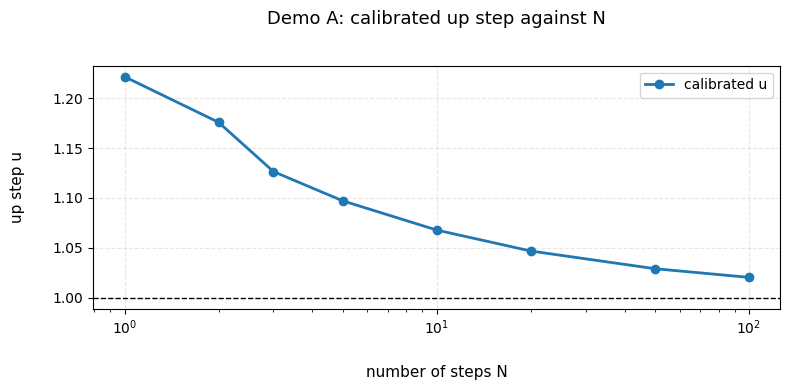

In [4]:
common = {"grid": True, "title_fontsize": 13, "label_fontsize": 11, "legend_fontsize": 10,
          "linewidth": 2, "markers": "o", "logx": True}
my_plotter(steps_list, u_list, names=["calibrated u"],
           layout={**common, "title": "Demo A: calibrated up step against N",
                   "x_label": "number of steps N", "y_label": "up step u", "hline": 1.0});

**Plot 2**: tree volatility against $N$ (log scale); dashed line $\sigma = 0.2$, the volatility of the market price

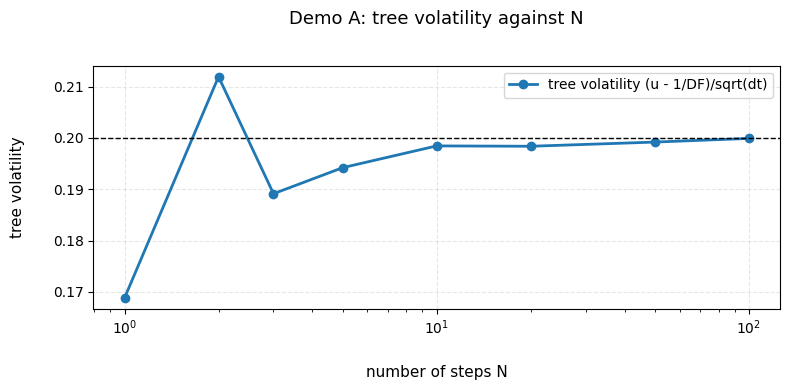

In [5]:
my_plotter(steps_list, vol_list, names=["tree volatility (u - 1/DF)/sqrt(dt)"],
           layout={**common, "title": "Demo A: tree volatility against N",
                   "x_label": "number of steps N", "y_label": "tree volatility",
                   "hline": sigma});

**Result**: $u \to 1$ and $d \to 1$ (the step $u - 1/DF$ shrinks like $\sqrt{\Delta t}$); the tree volatility goes to $\sigma = 0.2$ ($0.1688$ for $N = 1$, $0.1999$ for $N = 100$); for small $N$ it oscillates. Pricing errors are below $10^{-15}$.